## ToDo:

- x write simple function
- o check in with Sina
- x add to tutorial
- o write test

# Cascading of Tipping Events

As we have a feature for temporal correlation within a shift cluster, we can now think of ways on how to mimic local cascading events!

[Fig 1 of this puplication](https://link.springer.com/article/10.1007/s10712-024-09866-4/figures/1) suggests several tipping events that trigger each other or are simlutaneously triggered by an external event/forcing.

Idea-Pool:
- within a cluster mask, use Voronoi-Cells to distinguish tipping regions
- within each region, a shift event happens at a given time-offset
- neighbouring cells trigger each other -> shift moves stepwise through the whole cluster
- where is the first event? maybe different modes like central, boundaries, random
- fuzzy-up the edges to make it more natural


## Split up Mask in Voronoi Cells

In [8]:
import warnings
import numpy as np

def make_time_offsets(
        shape_mask,
        n_cells,
        max_offset=5,
        corr_seed=None,
):
    """
    y = latitudes
    x = longitudes
    """

    if corr_seed is not None:
        rng = np.random.RandomState(corr_seed)
    else:
        rng = np.random
        warnings.warn(
            "No random seed set for PONDS Correlation Method. Results will not be reproducible."
        )

    if n_cells > np.sum(shape_mask):
        raise ValueError(f"Can not fit {n_cells=} cell centers into shape mask with {shape_mask.sum()} cells.")
    if n_cells > np.sum(shape_mask)*0.5:
        print(f"Warning: Trying to fit {n_cells=} cell centers into shape mask with {shape_mask.sum()} cells. This may take a while.")

    # get bounding box of shape_mask True values
    latmin_ix, latmax_ix = np.where(np.any(shape_mask, axis=0))[0][[0, -1]]
    lonmin_ix, lonmax_ix = np.where(np.any(shape_mask, axis=1))[0][[0, -1]]

    # draw random unique cell centers within shape_mask
    sx = np.full(n_cells, -1, dtype=int)
    sy = np.full(n_cells, -1, dtype=int)
    # - draw cell centers
    for i in range(n_cells):
        sx[i] = rng.randint(lonmin_ix, lonmax_ix + 1, size=1)
        sy[i] = rng.randint(latmin_ix, latmax_ix + 1, size=1)
        pairs = np.column_stack((sx[:i+1],sy[:i+1]))
        # - 1) check if drawn cell centers are not unique; 2) check if drawn cell center is not in shape_mask
        while np.unique(pairs, axis=0).shape[0] < (i+1) or not(shape_mask[sx[i],sy[i]]):
            # - re-draw cell center
            sx[i] = rng.randint(lonmin_ix, lonmax_ix + 1, size=1)
            sy[i] = rng.randint(latmin_ix, latmax_ix + 1, size=1)
            pairs = np.column_stack((sx[:i+1],sy[:i+1]))

    # assign each seed a threshold value spanning the max_offset range
    offset_val = rng.randint(
        0, max_offset, size=n_cells
        )
    offset_mesh = np.array([np.full(shape_mask.shape, offset_val[i]) for i in range(n_cells)])


    # compute distance of each grid cell to each center
    yy, xx = np.mgrid[0:len(shape_mask), 0:len(shape_mask[0])]
    d2 = np.stack(
        [(yy - sx[i]) ** 2 + (xx - sy[i]) ** 2 for i in range(n_cells)], axis=0
    )
    mask_offset_ix = np.argmin(d2, axis=0)
    # construct mask_offset array: use offset values at the indices of the closest cell centers
    mask_offset = np.array([[offset_mesh[mask_offset_ix[i,j],i,j] for j in range(len(mask_offset_ix[0]))] for i in range(len(mask_offset_ix))])

    return mask_offset

In [9]:
import numpy as np
from ponds import ELLIPSIS, BLOB

lat_size = 200
lon_size = 200
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)

mask_gen = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=90,
    ecc_lon=150,
    )
mask_gen2 = BLOB(
    center_lat=0,
    center_lon=0,
    size=10,
)
mask = mask_gen2.make_shape(lats, lons)

#print(mask)

/tmp/ipykernel_23144/2551245139.py:37: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sx[i] = rng.randint(lonmin_ix, lonmax_ix + 1, size=1)
/tmp/ipykernel_23144/2551245139.py:38: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sy[i] = rng.randint(latmin_ix, latmax_ix + 1, size=1)
/tmp/ipykernel_23144/2551245139.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sx[i] = rng.randint(lonmin_ix, lonmax_ix + 1, size=1)
/tmp/ipykernel_23144/2551245139.py:44: DeprecationWa

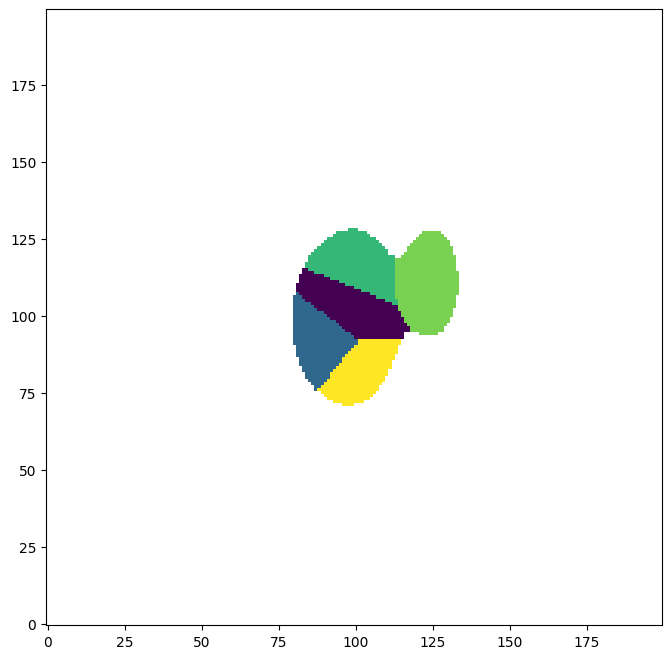

In [10]:
import matplotlib.pyplot as plt

mask_offset = make_time_offsets(
    shape_mask=mask,
    n_cells=5,
    corr_seed=3,
    max_offset=20,
)

voronoi_cells = np.full(mask.shape, np.nan)
voronoi_cells[mask] = mask_offset[mask]
#print(voronoi_cells)

plt.figure(figsize=(20,8))
plt.imshow(voronoi_cells, origin='lower')
plt.show()

## Linear Propagation through Cluster

[[1 1 1 ... 0 0 0]
 [1 1 1 ... 0 0 0]
 [1 1 1 ... 0 0 0]
 ...
 [7 7 7 ... 7 7 7]
 [7 7 7 ... 7 7 7]
 [7 7 7 ... 7 7 7]]


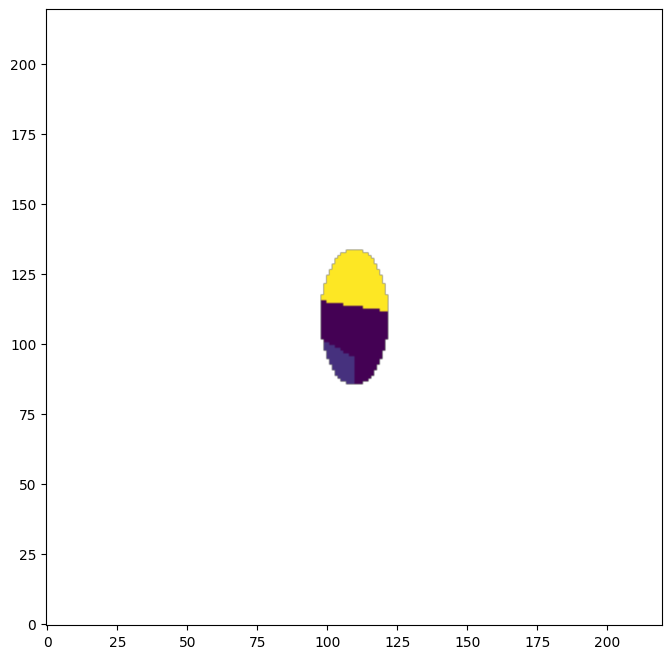

In [17]:
import numpy as np
from ponds import ELLIPSIS, Propagating

lat_size = 220
lon_size = 220
lats = np.linspace(-90, 90, lat_size)
lons = np.linspace(-180, 180, lon_size)

# Create a mask with an ellipsis shape
cluster = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=20,
    ecc_lon=20,
)
cluster_mask = cluster.make_shape(lats=lats, lons=lons)

corr = Propagating(
    n_cells=4,
    corr_seed=3,
    max_offset= 7,
)

shift_times = corr.make_time_offsets(
    cluster_mask,
)

print(shift_times)

voronoi_cells = np.full(cluster_mask.shape, np.nan)
voronoi_cells[cluster_mask] = shift_times[cluster_mask]

plt.figure(figsize=(20,8))
plt.imshow(voronoi_cells, origin='lower')
plt.show()

## Clustered Tipping

Cell Shape Center at lat: -12, lon: 151


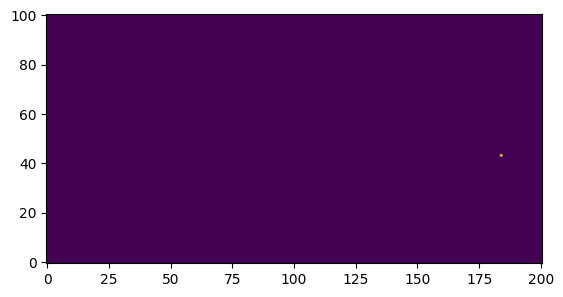

In [2]:
from ponds import PONDS, CELL
import matplotlib.pyplot as plt

ponds = PONDS(
    lat_size=101,
    lon_size=201,
)

cluster = CELL(
    #center_lat=0,
    #center_lon=0,
)
mask = cluster.make_shape(
    lats=ponds.lats,
    lons=ponds.lons,
)

plt.imshow(mask, origin='lower')
plt.show()

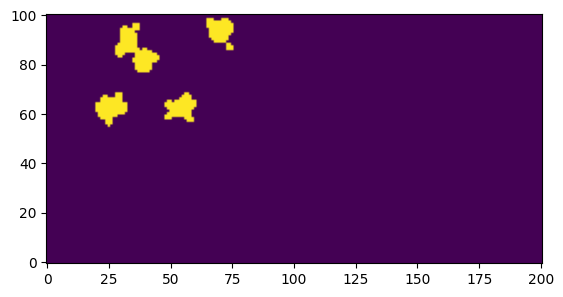

In [ ]:
from ponds import PONDS, CLUSTER, ELLIPSIS, BLOB
import matplotlib.pyplot as plt

ponds = PONDS(
    lat_size=101,
    lon_size=201,
)

cluster = CLUSTER(
    center_lat=40,
    center_lon=-100,
    size_lat=100,
    size_lon=100,
    n=5, 
    mode=BLOB(
        size=2,
    ),
)
mask = cluster.make_shape(
    lats=ponds.lats,
    lons=ponds.lons,
)

plt.imshow(mask, origin='lower')
plt.show()

## GiGi's Approach

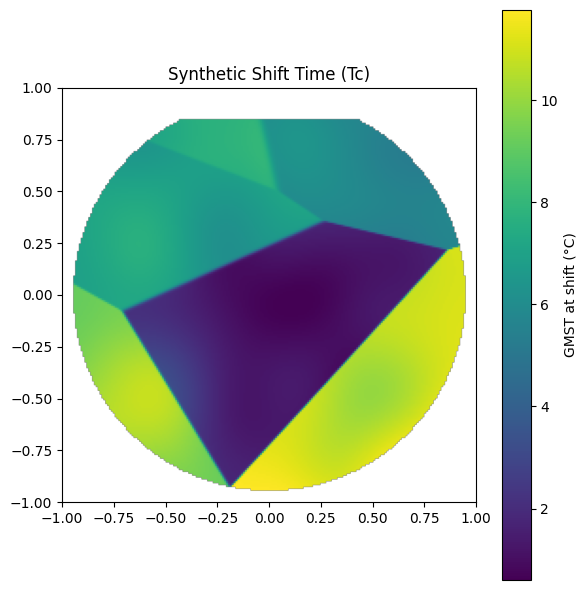

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# Synthetic "shift landscape" generator for TOAD testing
# Produces a 3D dataset (y, x, gmst) with adjacent regions tipping at different forcings
# and smooth transitions between regions. 
#
# Design choices:
# - gmst axis (0..14 °C) acts as the control parameter (like the colorbar in the example)
# - Regional heterogeneity is encoded as a smooth field of local thresholds Tc(y,x)
#   created by blending Voronoi-like regions with soft boundaries + additional
#   Gaussian-correlated texture via FFT filtering.
# - Each grid cell's observable ("ice_volume") drops sigmoidally when GMST exceeds Tc,
#   with spatially varying drop magnitude and duration, plus weak stochastic noise.

# -------------------------
# Helper: soft-Voronoi field
# -------------------------
def soft_voronoi_thresholds(
    nx, ny, n_seeds=7, gmst_min=0.0, gmst_max=14.0, boundary_softness=12.0, rng=None
):
    """
    Create a smooth field Tc(y,x) by seeding regions with different target thresholds
    and blending across boundaries using a softmin on distances (temperature-like).
    boundary_softness: larger -> sharper boundaries; smaller -> smoother blend.
    """
    if rng is None:
        rng = np.random.default_rng(42)
    # seed locations
    sx = rng.uniform(0, nx, size=n_seeds)
    sy = rng.uniform(0, ny, size=n_seeds)
    # assign each seed a threshold value spanning the gmst range
    seed_tc = rng.uniform(
        gmst_min + 1.0, gmst_max - 1.0, size=n_seeds
    )  # avoid hard edges

    # distance to each seed
    yy, xx = np.mgrid[0:ny, 0:nx]
    d2 = np.stack(
        [(xx - sx[i]) ** 2 + (yy - sy[i]) ** 2 for i in range(n_seeds)], axis=0
    )
    # soft assignment weights via softmax(-d * k)
    k = 1.0 / boundary_softness
    w = np.exp(-k * d2)
    w /= w.sum(axis=0, keepdims=True)
    Tc = (w * seed_tc[:, None, None]).sum(axis=0)
    return Tc, (sx, sy, seed_tc)


# -------------------------
# Helper: add correlated texture via FFT filtering
# -------------------------
def add_gaussian_texture(field, corr_len=18.0, amp=0.8, rng=None):
    """
    Adds smooth, zero-mean Gaussian-correlated noise to a 2D field using
    spectral filtering with an isotropic Gaussian kernel.
    corr_len: pixels; larger -> smoother variations
    amp: amplitude of texture to add (std units relative to field std)
    """
    if rng is None:
        rng = np.random.default_rng(123)
    ny, nx = field.shape
    noise = rng.normal(size=(ny, nx))
    ky = np.fft.fftfreq(ny)[:, None]
    kx = np.fft.fftfreq(nx)[None, :]
    k2 = kx**2 + ky**2
    # Gaussian in Fourier domain; avoid divide by zero
    sigma = 1.0 / (2.0 * np.pi * corr_len)
    filt = np.exp(-0.5 * (k2 / (sigma**2)))
    tex = np.fft.ifft2(np.fft.fft2(noise) * filt).real
    tex = (tex - tex.mean()) / (tex.std() + 1e-12)
    return field + amp * tex


# -------------------------
# Generator
# -------------------------
def make_dataset(nx=220, ny=220, gmst_max=14.0, n_seeds=7, seed=5):
    rng = np.random.default_rng(seed)
    gmst = np.linspace(0.0, gmst_max, 181)  # 0..14 °C in ~0.078°C steps

    # Spatial grid (Cartesian placeholder for polar stereographic plane)
    x = np.linspace(-1, 1, nx)
    y = np.linspace(-1, 1, ny)
    yy, xx = np.meshgrid(y, x, indexing="ij")

    # Optional "Antarctic-like" mask: keep a blobby disk to mimic a continent
    r = np.sqrt(xx**2 + yy**2)
    mask = (r <= 0.95) & (yy < 0.85)  # slightly flattened top edge

    # Smooth threshold field from soft-Voronoi regions
    Tc0, seeds = soft_voronoi_thresholds(
        nx,
        ny,
        n_seeds=n_seeds,
        gmst_min=0.0,
        gmst_max=gmst_max,
        boundary_softness=50.0,
        rng=rng,
    )
    # Add correlated heterogeneity
    Tc = add_gaussian_texture(Tc0, corr_len=20.0, amp=0.6, rng=rng)
    # Constrain to physical gmst range
    Tc = np.clip(Tc, 0.6, gmst_max - 0.6)

    # Spatially varying drop magnitude (0.2..1.0) and sharpness (duration proxy)
    drop_amp = 0.6 + 0.4 * rng.random((ny, nx))
    width = 0.18 + 0.14 * rng.random((ny, nx))  # sigmoid width in °C; small -> abrupt

    # Optional weak pre-shift trend and post-shift noise
    pretrend = 0.04 * (xx + 0.2 * yy)  # mild spatial gradient
    obs0 = 1.0 + pretrend  # baseline "ice volume" (normalized)

    # Build full field over gmst
    G = gmst[None, None, :]
    Tc3 = Tc[:, :, None]
    width3 = width[:, :, None]
    amp3 = drop_amp[:, :, None]

    # Sigmoid drop when gmst exceeds Tc (smooth "abrupt" shift)
    # ice_volume = baseline - amp * sigmoid((gmst - Tc)/width) + small noise
    sig = 1.0 / (1.0 + np.exp(-(G - Tc3) / width3))
    ice = obs0[:, :, None] - amp3 * sig

    # Add weak spatially and gmst-dependent noise (heteroscedastic)
    noise = 0.02 * (1 + 0.2 * (G / gmst_max)) * rng.normal(size=ice.shape)
    ice = ice + noise

    # Mask ocean/outside region with NaNs
    ice[~mask, :] = np.nan
    Tc_masked = Tc.copy()
    Tc_masked[~mask] = np.nan

    # Package as xarray Dataset
    ds = xr.Dataset(
        {
            "ice_volume": (("y", "x", "gmst"), ice.astype(np.float32)),
            "shift_time": (("y", "x"), Tc_masked.astype(np.float32)),
            "drop_amplitude": (("y", "x"), drop_amp.astype(np.float32)),
            "width": (("y", "x"), width.astype(np.float32)),
            "mask": (("y", "x"), mask.astype(np.int8)),
        },
        coords={"y": y, "x": x, "gmst": gmst},
        attrs={
            "description": "Synthetic shift-landscape dataset for TOAD testing; gmst is the control parameter."
        },
    )
    return ds


ds = make_dataset()

# Quick-look plot of shift_time (like the example; using default matplotlib settings)
plt.figure(figsize=(6, 6))
im = plt.imshow(
    ds["shift_time"],
    origin="lower",
    extent=[ds.x.min(), ds.x.max(), ds.y.min(), ds.y.max()],
)
plt.colorbar(im, label="GMST at shift (°C)")
plt.title("Synthetic Shift Time (Tc)")
plt.tight_layout()